In [2]:
from src import SV_configs
from src import utils
from src import linear_RNN
import seaborn as sns
import numpy as np
import pandas as pd
from types import SimpleNamespace
import matplotlib.pyplot as plt

Step 1:

Rotation matrix R:
[[ 1. -0.]
 [ 0.  1.]]

U (left singular vectors, should be a rotation matrix):
[[1. 0.]
 [0. 1.]]

Singular values (should be [1,1] for a pure rotation):
[1. 1.]

V^T (right singular vectors, should be a rotation matrix):
[[1. 0.]
 [0. 1.]]

Determinant of U: 1.0
Determinant of V: 1.0

Reconstructed R (should be equal to original R):
[[1. 0.]
 [0. 1.]]

----------------------------------------

Step 2:

Rotation matrix R:
[[ 0.95105652 -0.30901699]
 [ 0.30901699  0.95105652]]

U (left singular vectors, should be a rotation matrix):
[[-0.30901699 -0.95105652]
 [ 0.95105652 -0.30901699]]

Singular values (should be [1,1] for a pure rotation):
[1. 1.]

V^T (right singular vectors, should be a rotation matrix):
[[ 0.  1.]
 [-1. -0.]]

Determinant of U: 0.9999999999999999
Determinant of V: 1.0

Reconstructed R (should be equal to original R):
[[ 0.95105652 -0.30901699]
 [ 0.30901699  0.95105652]]

----------------------------------------

Step 3:

Rotation matri

In [4]:
# example task function
def generate_unaligned_teacher_data(args, variance): # (one seed)
    X = np.random.normal(0, 0.01, size=(args.num_samples, args.trajectory_length*args.input_size)).astype(float) 
    X = utils.whiten(X).reshape(args.num_samples, args.trajectory_length, args.input_size)
    teacher_W_x = np.random.normal(loc=0.0, scale = variance, size=(args.hidden_size, args.input_size))
    teacher_W_h = np.random.normal(loc=0.0, scale = variance, size=(args.hidden_size, args.hidden_size))
    teacher_W_y = np.random.normal(loc=0.0, scale = variance, size=(args.output_size, args.hidden_size))
    h_t = np.zeros((args.num_samples, args.hidden_size))
    h_trajectory = np.zeros((args.num_samples, args.trajectory_length, args.hidden_size))
    for t in range(args.trajectory_length):
        h_t = np.einsum("ij,bj->bi", teacher_W_h, h_t) + np.einsum("ij,bj->bi", teacher_W_x, X[:,t])
    y_t = np.einsum("ij,bj->bi", teacher_W_y, h_t)
    y = y_t.reshape(y_t.shape[0], 1, -1)
    
    return X, y, teacher_W_x, teacher_W_h, teacher_W_y

In [5]:
def kernel_distance(A,B):
    # Extract matrices K_t1 and K_t2
    K_t1 = A
    K_t2 = B
    # Compute the Frobenius inner product
    inner_product = np.sum(K_t1 * K_t2)
    # Compute the Frobenius norms
    norm_t1 = np.linalg.norm(K_t1, 'fro')
    norm_t2 = np.linalg.norm(K_t2, 'fro')
    # Compute the similarity measure
    S_t1_t2 = 1 - inner_product / (norm_t1 * norm_t2)
    return S_t1_t2

In [4]:
lenght = np.linspace(0.01, 1, 2)
scale = np.linspace(0.01, 1, 3)
seeds = [4,6,7,8]

#TO: for differnet time steps
NTK_1 = {}
losses = {}
kernel_distances= {}
kernel_distances_seeds = {}
for s in scale:
    for l in lenght:
        for seed in seeds:
            traj_1_args = {
                'data_out_dir': 'data/',
                'results_out_dir': 'results/',
                'name': 'unaligned',
                'num_seeds': seed,
                # to run over more seeds which need to be specified as arguments (see simulate.py for example)
                'override_load': False,
                'trajectory_length': 1,
                'num_samples': 50,
                'num_epochs': 30000,
                'lr': 0.1,
                'initialization_scale': 0.01,  # (variance of the 0-mean initialized weights when the network is unaligned)
                'input_size': 4,
                'hidden_size': 4,
                'output_size': 4,
                'S_config': ['exponential', 'exponential', 'exponential', 'exponential'],
                # data dynamics: constant (lambda_t=1-- overrides the lambda_0 argument), exponential (lambda_t=lambda^t), inverse-exponential (lambda_t=lambda^{T-t})
                'delta': [1, 1, 1, 1],  # data dynamics scaling-term (i.e., s_t = delta*lambda_t) for each SV dimension
                'lambda_0': [1, 1, 1, 1],  # data dynamics temporal-term
                'S_T': [1, 1, 1, 1],  # SV at last timestep (feedforward)
                'S_TeqS_t': True,  # whether SV at last timestep follows the data dynamics (if true, ignores S_T argument)
                'zero_balanced': True,  # if true, sets a=c at initialization (for aligned weights)
                'frozen_hidden_layer': False,  # freezes learning on recurrent layer
                'frozen_input_output': False,  # freezes learning on input-output layers
                'single_output_y': True,
                # only computes loss on y_T (ignores y_1 to y_{T-1}); code not compatible with the multi-output case at the moment
                'inout_mode_init': [l, l, l, l],
                # input-output mode initialization for each dimension (when weights are aligned and input-output are zero-balanced)
                'in_mode_init':  [0.7, 0.7, 0.7, 0.7],
                # input mode initialization for each dimension (when input-output weights are not zero-balanced)
                'out_mode_init': [0.7, 0.7, 0.7, 0.7],  # output ""
                'rec_mode_init': [s, s, s, s],  # recurrent ""
                'num_SV': 4,  # num of SV dimensions (should be equal to input=hidden=output sizes)
                'aligned_student_weights': True,
                # if False, random weights ; if True, aligned to SV data dynamics specified above
                'log_H': False,
                'log_y_hat': False,
                'compute_NTK': True,
                'nonlinear_RNN': False,
                'log_every_e_epoch': 100,  # how many gradient steps until logging metrics
                'subsample_NTK': False,  # whether to use a subsample of data when computing NTK
            'single_output_rotation': False
            }
            traj_1_args = SimpleNamespace(**traj_1_args)
            traj_1_tape = utils.get_tape_module(traj_1_args)
            traj_1_data_tape = utils.get_data_tape(traj_1_args)
            seed = 0
            utils.set_seeds(seed)
        
            ## --- generating tasks ----
            ## example 1: generating data from SV data dynamics specified in arguments
            traj_1_args.S = SV_configs.create_SV_trajectories(traj_1_args)
            traj_1_data_tape = utils.generate_data_multiseed(traj_1_args, traj_1_data_tape, seed)
        
            ## example 2: generating data from a random unaligned teacher (or could be anything else)
            # traj_1_X, traj_1_y, traj_1_t_W_x, traj_1_t_W_h, traj_1_t_W_y = generate_unaligned_teacher_data(traj_1_args, variance=0.1)
            # traj_1_data_tape.X[seed] = traj_1_X
            # traj_1_data_tape.y[seed] = traj_1_y
        
            ## --- generating LRNN ----
            ## example 1: aligned RNN (NOTE: not set up to align to any given task; has to be generated from SV data dynamics specified in arguments)
            ## so don't combine aligned RNN + unaligned teacher unless new implementation
            traj_1_tape = utils.initialize_student_multiseed(traj_1_args, traj_1_data_tape, seed, traj_1_tape)
        
            # example 2: unaligned RNN
            # traj_1_tape = utils.initialize_unaligned_student(traj_1_args, seed, traj_1_tape)
        
            # --- model initialization, training, modes, NTK ---
            traj_1_model = linear_RNN.LinearRNN_multiseed(traj_1_args, traj_1_tape, seed)
            traj_1_model.train(traj_1_data_tape.X[seed], traj_1_data_tape.y[seed])
            traj_1_model.project_SVD_space(
                traj_1_data_tape)  # computes modes for aligned network; computes SV for unaligned network
            traj_1_model.compute_NTK(traj_1_data_tape.X[seed], traj_1_data_tape.y[seed], seed)
            traj_1_tape = traj_1_model.tape
        
            # ntks_empirical[(lmda, scale)] = np.array(
            #     [get_ntk(w1w1, w2w2, X, out_dim) for (w1w1, w2w2) in zip(w1w1s_empirical[(lmda, scale)], w2w2s_empirical[(lmda, scale)])])
            reshaped_NTK_3D_traj_1 = traj_1_tape.NTK[seed].reshape(
                int(traj_1_args.num_epochs / traj_1_args.log_every_e_epoch),
                traj_1_args.num_samples * traj_1_args.output_size,
                traj_1_args.num_samples * traj_1_args.output_size
            )
            kernel_distances_seeds[(seed)] = kernel_distance(reshaped_NTK_3D_traj_1[0, :, :], reshaped_NTK_3D_traj_1[-1, :, :])
            average_kernel_distance_over_seeds = np.mean(list(kernel_distances_seeds.values()))
        
        kernel_distances[(l, s)] = average_kernel_distance_over_seeds  
        NTK_1[(l, s)] = reshaped_NTK_3D_traj_1
        losses[(l, s)] = traj_1_tape.loss[seed]




In [5]:
lenght = np.linspace(0.01, 1, 2)
scale = np.linspace(0.01, 1, 3)

#TO: for differnet time steps
NTK_2 = {}
losses = {}
kernel_distances= {}
for s in scale:
    for l in lenght:
        traj_1_args = {
            'data_out_dir': 'data/',
            'results_out_dir': 'results/',
            'name': 'unaligned',
            'num_seeds': 1,
            # to run over more seeds which need to be specified as arguments (see simulate.py for example)
            'override_load': False,
            'trajectory_length': 2,
            'num_samples': 50,
            'num_epochs': 30000,
            'lr': 0.1,
            'initialization_scale': 0.01,  # (variance of the 0-mean initialized weights when the network is unaligned)
            'input_size': 4,
            'hidden_size': 4,
            'output_size': 4,
            'S_config': ['exponential', 'exponential', 'exponential', 'exponential'],
            # data dynamics: constant (lambda_t=1-- overrides the lambda_0 argument), exponential (lambda_t=lambda^t), inverse-exponential (lambda_t=lambda^{T-t})
            'delta': [1, 1, 1, 1],  # data dynamics scaling-term (i.e., s_t = delta*lambda_t) for each SV dimension
            'lambda_0': [1, 1, 1, 1],  # data dynamics temporal-term
            'S_T': [1, 1, 1, 1],  # SV at last timestep (feedforward)
            'S_TeqS_t': True,  # whether SV at last timestep follows the data dynamics (if true, ignores S_T argument)
            'zero_balanced': True,  # if true, sets a=c at initialization (for aligned weights)
            'frozen_hidden_layer': False,  # freezes learning on recurrent layer
            'frozen_input_output': False,  # freezes learning on input-output layers
            'single_output_y': True,
            # only computes loss on y_T (ignores y_1 to y_{T-1}); code not compatible with the multi-output case at the moment
            'inout_mode_init': [l, l, l, l],
            # input-output mode initialization for each dimension (when weights are aligned and input-output are zero-balanced)
            'in_mode_init':  [0.7, 0.7, 0.7, 0.7],
            # input mode initialization for each dimension (when input-output weights are not zero-balanced)
            'out_mode_init': [0.7, 0.7, 0.7, 0.7],  # output ""
            'rec_mode_init': [s, s, s, s],  # recurrent ""
            'num_SV': 4,  # num of SV dimensions (should be equal to input=hidden=output sizes)
            'aligned_student_weights': True,
            # if False, random weights ; if True, aligned to SV data dynamics specified above
            'log_H': False,
            'log_y_hat': False,
            'compute_NTK': True,
            'nonlinear_RNN': False,
            'log_every_e_epoch': 100,  # how many gradient steps until logging metrics
            'subsample_NTK': False,  # whether to use a subsample of data when computing NTK
            'single_output_rotation': False
        }
        traj_1_args = SimpleNamespace(**traj_1_args)
        traj_1_tape = utils.get_tape_module(traj_1_args)
        traj_1_data_tape = utils.get_data_tape(traj_1_args)
        seed = 0
        utils.set_seeds(seed)

        ## --- generating tasks ----
        ## example 1: generating data from SV data dynamics specified in arguments
        traj_1_args.S = SV_configs.create_SV_trajectories(traj_1_args)
        traj_1_data_tape = utils.generate_data_multiseed(traj_1_args, traj_1_data_tape, seed)

        ## example 2: generating data from a random unaligned teacher (or could be anything else)
        # traj_1_X, traj_1_y, traj_1_t_W_x, traj_1_t_W_h, traj_1_t_W_y = generate_unaligned_teacher_data(traj_1_args, variance=0.1)
        # traj_1_data_tape.X[seed] = traj_1_X
        # traj_1_data_tape.y[seed] = traj_1_y

        ## --- generating LRNN ----
        ## example 1: aligned RNN (NOTE: not set up to align to any given task; has to be generated from SV data dynamics specified in arguments)
        ## so don't combine aligned RNN + unaligned teacher unless new implementation
        traj_1_tape = utils.initialize_student_multiseed(traj_1_args, traj_1_data_tape, seed, traj_1_tape)

        # example 2: unaligned RNN
        # traj_1_tape = utils.initialize_unaligned_student(traj_1_args, seed, traj_1_tape)

        # --- model initialization, training, modes, NTK ---
        traj_1_model = linear_RNN.LinearRNN_multiseed(traj_1_args, traj_1_tape, seed)
        traj_1_model.train(traj_1_data_tape.X[seed], traj_1_data_tape.y[seed])
        traj_1_model.project_SVD_space(
            traj_1_data_tape)  # computes modes for aligned network; computes SV for unaligned network
        traj_1_model.compute_NTK(traj_1_data_tape.X[seed], traj_1_data_tape.y[seed], seed)
        traj_1_tape = traj_1_model.tape

        # ntks_empirical[(lmda, scale)] = np.array(
        #     [get_ntk(w1w1, w2w2, X, out_dim) for (w1w1, w2w2) in zip(w1w1s_empirical[(lmda, scale)], w2w2s_empirical[(lmda, scale)])])
        reshaped_NTK_3D_traj_1 = traj_1_tape.NTK[seed].reshape(
            int(traj_1_args.num_epochs / traj_1_args.log_every_e_epoch),
            traj_1_args.num_samples * traj_1_args.output_size,
            traj_1_args.num_samples * traj_1_args.output_size
        )

        kernel_distances[(l, s)] = kernel_distance(reshaped_NTK_3D_traj_1[0, :, :], reshaped_NTK_3D_traj_1[-1, :, :])
        NTK_2[(l, s)] = reshaped_NTK_3D_traj_1
        losses[(l, s)] = traj_1_tape.loss[seed]




In [6]:
lenght = np.linspace(0.01, 1, 2)
scale = np.linspace(0.01, 1, 3)

#TO: for differnet time steps
NTK_3 = {}
losses = {}
kernel_distances= {}
for s in scale:
    for l in lenght:
        traj_1_args = {
            'data_out_dir': 'data/',
            'results_out_dir': 'results/',
            'name': 'unaligned',
            'num_seeds': 1,
            # to run over more seeds which need to be specified as arguments (see simulate.py for example)
            'override_load': False,
            'trajectory_length': 5,
            'num_samples': 50,
            'num_epochs': 30000,
            'lr': 0.1,
            'initialization_scale': 0.01,  # (variance of the 0-mean initialized weights when the network is unaligned)
            'input_size': 4,
            'hidden_size': 4,
            'output_size': 4,
            'S_config': ['exponential', 'exponential', 'exponential', 'exponential'],
            # data dynamics: constant (lambda_t=1-- overrides the lambda_0 argument), exponential (lambda_t=lambda^t), inverse-exponential (lambda_t=lambda^{T-t})
            'delta': [1, 1, 1, 1],  # data dynamics scaling-term (i.e., s_t = delta*lambda_t) for each SV dimension
            'lambda_0': [1, 1, 1, 1],  # data dynamics temporal-term
            'S_T': [1, 1, 1, 1],  # SV at last timestep (feedforward)
            'S_TeqS_t': True,  # whether SV at last timestep follows the data dynamics (if true, ignores S_T argument)
            'zero_balanced': True,  # if true, sets a=c at initialization (for aligned weights)
            'frozen_hidden_layer': False,  # freezes learning on recurrent layer
            'frozen_input_output': False,  # freezes learning on input-output layers
            'single_output_y': True,
            # only computes loss on y_T (ignores y_1 to y_{T-1}); code not compatible with the multi-output case at the moment
            'inout_mode_init': [l, l, l, l],
            # input-output mode initialization for each dimension (when weights are aligned and input-output are zero-balanced)
            'in_mode_init':  [0.7, 0.7, 0.7, 0.7],
            # input mode initialization for each dimension (when input-output weights are not zero-balanced)
            'out_mode_init': [0.7, 0.7, 0.7, 0.7],  # output ""
            'rec_mode_init': [s, s, s, s],  # recurrent ""
            'num_SV': 4,  # num of SV dimensions (should be equal to input=hidden=output sizes)
            'aligned_student_weights': True,
            # if False, random weights ; if True, aligned to SV data dynamics specified above
            'log_H': False,
            'log_y_hat': False,
            'compute_NTK': True,
            'nonlinear_RNN': False,
            'log_every_e_epoch': 100,  # how many gradient steps until logging metrics
            'subsample_NTK': False,  # whether to use a subsample of data when computing NTK
            'single_output_rotation': False
        }
        traj_1_args = SimpleNamespace(**traj_1_args)
        traj_1_tape = utils.get_tape_module(traj_1_args)
        traj_1_data_tape = utils.get_data_tape(traj_1_args)
        seed = 0
        utils.set_seeds(seed)

        ## --- generating tasks ----
        ## example 1: generating data from SV data dynamics specified in arguments
        traj_1_args.S = SV_configs.create_SV_trajectories(traj_1_args)
        traj_1_data_tape = utils.generate_data_multiseed(traj_1_args, traj_1_data_tape, seed)

        ## example 2: generating data from a random unaligned teacher (or could be anything else)
        # traj_1_X, traj_1_y, traj_1_t_W_x, traj_1_t_W_h, traj_1_t_W_y = generate_unaligned_teacher_data(traj_1_args, variance=0.1)
        # traj_1_data_tape.X[seed] = traj_1_X
        # traj_1_data_tape.y[seed] = traj_1_y

        ## --- generating LRNN ----
        ## example 1: aligned RNN (NOTE: not set up to align to any given task; has to be generated from SV data dynamics specified in arguments)
        ## so don't combine aligned RNN + unaligned teacher unless new implementation
        traj_1_tape = utils.initialize_student_multiseed(traj_1_args, traj_1_data_tape, seed, traj_1_tape)

        # example 2: unaligned RNN
        # traj_1_tape = utils.initialize_unaligned_student(traj_1_args, seed, traj_1_tape)

        # --- model initialization, training, modes, NTK ---
        traj_1_model = linear_RNN.LinearRNN_multiseed(traj_1_args, traj_1_tape, seed)
        traj_1_model.train(traj_1_data_tape.X[seed], traj_1_data_tape.y[seed])
        traj_1_model.project_SVD_space(
            traj_1_data_tape)  # computes modes for aligned network; computes SV for unaligned network
        traj_1_model.compute_NTK(traj_1_data_tape.X[seed], traj_1_data_tape.y[seed], seed)
        traj_1_tape = traj_1_model.tape

        # ntks_empirical[(lmda, scale)] = np.array(
        #     [get_ntk(w1w1, w2w2, X, out_dim) for (w1w1, w2w2) in zip(w1w1s_empirical[(lmda, scale)], w2w2s_empirical[(lmda, scale)])])
        reshaped_NTK_3D_traj_1 = traj_1_tape.NTK[seed].reshape(
            int(traj_1_args.num_epochs / traj_1_args.log_every_e_epoch),
            traj_1_args.num_samples * traj_1_args.output_size,
            traj_1_args.num_samples * traj_1_args.output_size
        )

        kernel_distances[(l, s)] = kernel_distance(reshaped_NTK_3D_traj_1[0, :, :], reshaped_NTK_3D_traj_1[-1, :, :])
        NTK_3[(l, s)] = reshaped_NTK_3D_traj_1
        losses[(l, s)] = traj_1_tape.loss[seed]

In [7]:
# na = not aligned
l_values_1 = sorted(set(key[0] for key in NTK_1))
s_values_1 = sorted(set(key[1] for key in NTK_1))

steps_of_interest =[-1]
kernel_heatmaps_1 = {step: pd.DataFrame(np.nan, index=l_values_1, columns=s_values_1 ) for step in steps_of_interest}

# Populate the heatmaps
for step in steps_of_interest:
    for (param1, param2), distances in NTK_1.items():
        if step <= len(distances):  # Ensure the step exists in the data
            kernel_heatmaps_1[step].loc[param1, param2] =   kernel_distance(distances[0, :, :],distances[step, :, :] ) # Adjust for 0-based indexing
            #kernel_distance(reshaped_NTK_3D_traj_1[0, :, :], reshaped_NTK_3D_traj_1[-1, :, :])
    
# Use the scale of the last kernel heatmap and the first loss heatmap
kernel_scale_1 = kernel_heatmaps_1[steps_of_interest[-1]]  # Last kernel heatmap

vmin_kernel_1 = kernel_scale_1.min().min()
vmax_kernel_1 = kernel_scale_1.max().max()

# a = aligned
l_values_2 = sorted(set(key[0] for key in NTK_2))
s_values_2 = sorted(set(key[1] for key in NTK_2))

kernel_heatmaps_2 = {step: pd.DataFrame(np.nan, index=l_values_2, columns=s_values_2 ) for step in steps_of_interest}

# Populate the heatmaps
for step in steps_of_interest:
    for (param1, param2), distances in NTK_2.items():
        if step <= len(distances):  # Ensure the step exists in the data
            kernel_heatmaps_2[step].loc[param1, param2] =   kernel_distance(distances[0, :, :],distances[step, :, :] )# Adjust for 0-based indexing
            #kernel_distance(reshaped_NTK_3D_traj_1[0, :, :], reshaped_NTK_3D_traj_1[-1, :, :])
    
# Use the scale of the last kernel heatmap and the first loss heatmap
kernel_scale_2 = kernel_heatmaps_2[steps_of_interest[-1]]  # Last kernel heatmap

vmin_kernel_2 = kernel_scale_2.min().min()
vmax_kernel_2 = kernel_scale_2.max().max()

# a = aligned
l_values_3 = sorted(set(key[0] for key in NTK_3))
s_values_3 = sorted(set(key[1] for key in NTK_3))

kernel_heatmaps_3 = {step: pd.DataFrame(np.nan, index=l_values_3, columns=s_values_3 ) for step in steps_of_interest}

# Populate the heatmaps
for step in steps_of_interest:
    for (param1, param2), distances in NTK_3.items():
        if step <= len(distances):  # Ensure the step exists in the data
            kernel_heatmaps_3[step].loc[param1, param2] =   kernel_distance(distances[0, :, :],distances[step, :, :] )# Adjust for 0-based indexing
            #kernel_distance(reshaped_NTK_3D_traj_1[0, :, :], reshaped_NTK_3D_traj_1[-1, :, :])
    
# Use the scale of the last kernel heatmap and the first loss heatmap
kernel_scale_3 = kernel_heatmaps_3[steps_of_interest[-1]]  # Last kernel heatmap

vmin_kernel_3 = kernel_scale_3.min().min()
vmax_kernel_3 = kernel_scale_3.max().max()

# Shared color maps for kernel distance and loss
cmap_kernel_1 = 'coolwarm'
cmap_kernel_2 = 'coolwarm'
cmap_kernel_3 = 'coolwarm'
# Plot kernel distance and loss heatmaps for each step

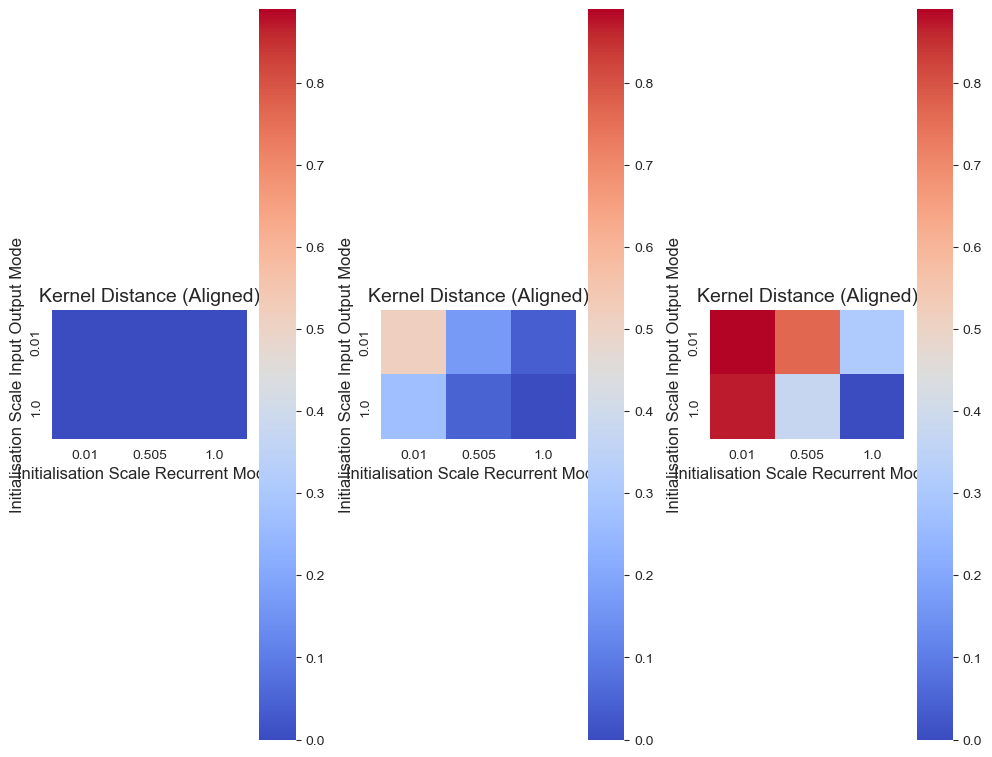

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

# Adjusted figure size to make it more compact
fig, axes = plt.subplots(1, 3, figsize=(10, 10))

# Shared color range for both heatmaps
vmin = min(min(vmin_kernel_1, vmin_kernel_2), vmin_kernel_3)
vmax = max(max(vmax_kernel_1, vmax_kernel_2), vmax_kernel_3)

# Plot heatmap for not aligned (na)
sns.heatmap(kernel_heatmaps_1[step],
            ax=axes[0],
            xticklabels=True,  # Show x-axis tick labels
            yticklabels=True,  # Show y-axis tick labels
            cmap='coolwarm',  # Retain the original color map
            cbar=True,  # Show color bar
            vmin=vmin, vmax=vmax,  # Apply consistent color scale
            square=True)
axes[0].set_title('Kernel Distance (Aligned)', fontsize=14)
axes[0].set_xlabel('Initialisation Scale Recurrent Modes', fontsize=12)
axes[0].set_ylabel('Initialisation Scale Input Output Mode', fontsize=12)
axes[0].tick_params(axis='both', which='major', labelsize=10)

# Plot heatmap for aligned (a)
sns.heatmap(kernel_heatmaps_2[step],
            ax=axes[1],
            xticklabels=True,  # Show x-axis tick labels
            yticklabels=True,  # Show y-axis tick labels
            cmap='coolwarm',  # Retain the original color map
            cbar=True,  # Show color bar
            vmin=vmin, vmax=vmax,  # Apply consistent color scale
            square=True)
axes[1].set_title('Kernel Distance (Aligned)', fontsize=14)
axes[1].set_xlabel('Initialisation Scale Recurrent Modes', fontsize=12)
axes[1].set_ylabel('Initialisation Scale Input Output Mode', fontsize=12)
axes[1].tick_params(axis='both', which='major', labelsize=10)

# Plot heatmap for aligned (a)
sns.heatmap(kernel_heatmaps_3[step],
            ax=axes[2],
            xticklabels=True,  # Show x-axis tick labels
            yticklabels=True,  # Show y-axis tick labels
            cmap='coolwarm',  # Retain the original color map
            cbar=True,  # Show color bar
            vmin=vmin, vmax=vmax,  # Apply consistent color scale
            square=True)
axes[2].set_title('Kernel Distance (Aligned)', fontsize=14)
axes[2].set_xlabel('Initialisation Scale Recurrent Modes', fontsize=12)
axes[2].set_ylabel('Initialisation Scale Input Output Mode', fontsize=12)
axes[2].tick_params(axis='both', which='major', labelsize=10)

# Adjust layout for better spacing and compactness
plt.tight_layout(pad=1)  # Reduce padding between subplots
plt.show()


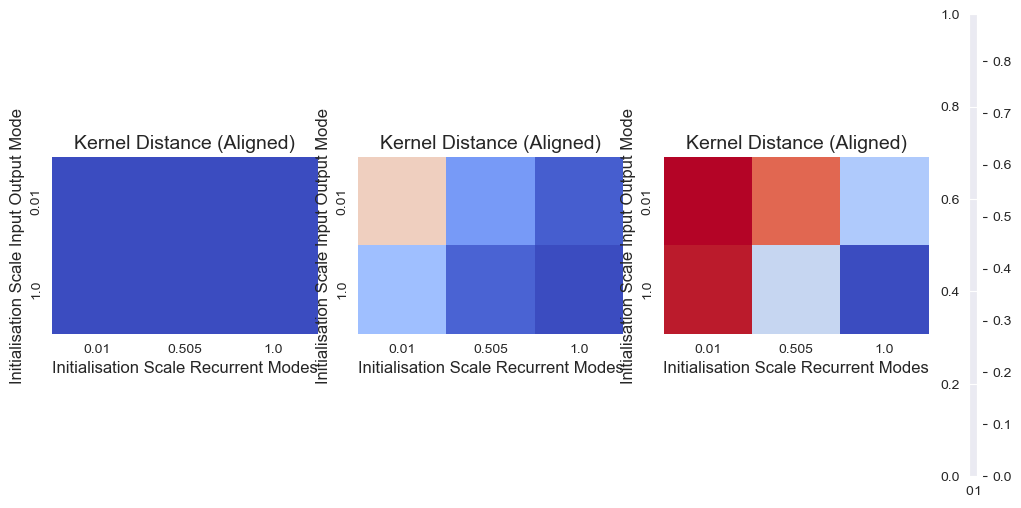

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns
from mpl_toolkits.axes_grid1 import make_axes_locatable

# Adjusted figure size
fig, axes = plt.subplots(1, 4, figsize=(12, 6), 
                         gridspec_kw={'width_ratios': [1, 1, 1, 0.05]})  # Last subplot for colorbar

# Shared color range for all heatmaps
vmin = min(vmin_kernel_1, vmin_kernel_2, vmin_kernel_3)
vmax = max(vmax_kernel_1, vmax_kernel_2, vmax_kernel_3)

# Create heatmaps without individual colorbars
heatmaps = []
for i, kernel in enumerate([kernel_heatmaps_1, kernel_heatmaps_2, kernel_heatmaps_3]):
    heatmaps.append(
        sns.heatmap(kernel[step],
                    ax=axes[i],
                    xticklabels=True,
                    yticklabels=True,
                    cmap='coolwarm',
                    cbar=False,  # Disable individual colorbars
                    vmin=vmin, vmax=vmax,
                    square=True)
    )
    axes[i].set_title('Kernel Distance (Aligned)', fontsize=14)
    axes[i].set_xlabel('Initialisation Scale Recurrent Modes', fontsize=12)
    axes[i].set_ylabel('Initialisation Scale Input Output Mode', fontsize=12)
    axes[i].tick_params(axis='both', which='major', labelsize=10)

# Create a single shared colorbar
divider = make_axes_locatable(axes[-1])  # Attach to the last subplot
cax = divider.append_axes("right", size="5%", pad=0.05)  # Adjust size and padding
cbar = fig.colorbar(heatmaps[0].collections[0], cax=cax)  # Use first heatmap

plt.show()

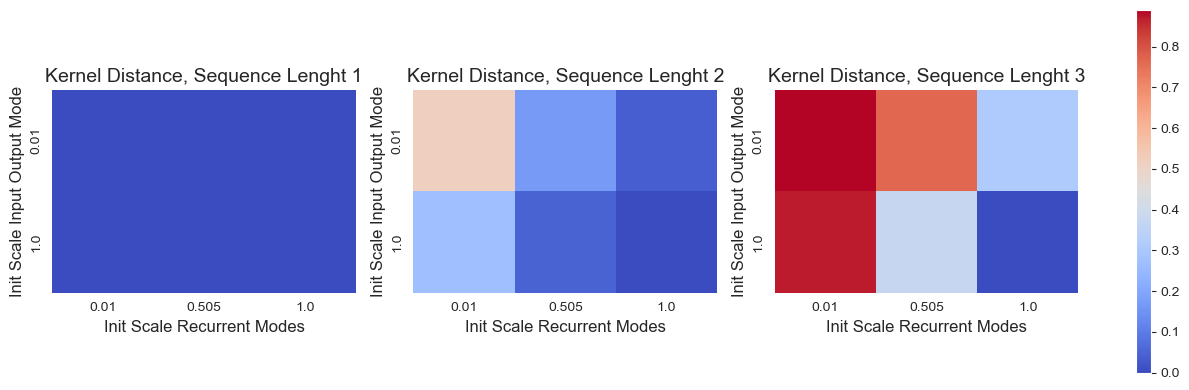

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

# Adjusted figure size & grid specifications
fig, axes = plt.subplots(1, 4, figsize=(12, 4), 
                         gridspec_kw={'width_ratios': [1, 1, 1, 0.05]})  # Last subplot for colorbar

# Shared color range for all heatmaps
vmin = min(vmin_kernel_1, vmin_kernel_2, vmin_kernel_3)
vmax = max(vmax_kernel_1, vmax_kernel_2, vmax_kernel_3)

# Create heatmaps without individual colorbars
heatmaps = []
for i, kernel in enumerate([kernel_heatmaps_1, kernel_heatmaps_2, kernel_heatmaps_3]):
    heatmaps.append(
        sns.heatmap(kernel[step],
                    ax=axes[i],
                    xticklabels=True,
                    yticklabels=True,
                    cmap='coolwarm',
                    cbar=False,  # Disable individual colorbars
                    vmin=vmin, vmax=vmax,
                    square=True)
    )
    axes[i].set_title(f'Kernel Distance, Sequence Lenght {i+1}', fontsize=14)
    axes[i].set_xlabel('Init Scale Recurrent Modes', fontsize=12)
    axes[i].set_ylabel('Init Scale Input Output Mode', fontsize=12)
    axes[i].tick_params(axis='both', which='major', labelsize=10)

# Add a **shared colorbar** in the last subplot
cbar_ax = axes[3]  # Use the last axis slot for the colorbar
fig.colorbar(heatmaps[0].collections[0], cax=cbar_ax)  # Use first heatmap's colorbar

# Improve layout
plt.tight_layout()
plt.show()


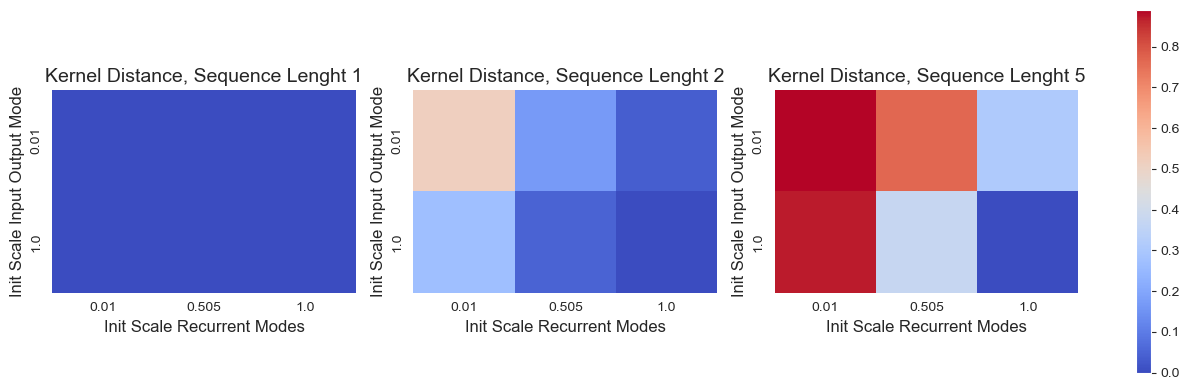

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

# Adjusted figure size & grid specifications
fig, axes = plt.subplots(1, 4, figsize=(12, 4), 
                         gridspec_kw={'width_ratios': [1, 1, 1, 0.05]})  # Last subplot for colorbar

# Shared color range for all heatmaps
vmin = min(vmin_kernel_1, vmin_kernel_2, vmin_kernel_3)
vmax = max(vmax_kernel_1, vmax_kernel_2, vmax_kernel_3)

# Create heatmaps without individual colorbars
heatmaps = []
for i, kernel in enumerate([kernel_heatmaps_1, kernel_heatmaps_2, kernel_heatmaps_3]):
    if i == 2:
        k= i+2
    else:
        k=i
    heatmaps.append(
        sns.heatmap(kernel[step],
                    ax=axes[i],
                    xticklabels=True,
                    yticklabels=True,
                    cmap='coolwarm',
                    cbar=False,  # Disable individual colorbars
                    vmin=vmin, vmax=vmax,
                    square=True)
    )
    axes[i].set_title(f'Kernel Distance, Sequence Lenght {k+1}', fontsize=14)
    axes[i].set_xlabel('Init Scale Recurrent Modes', fontsize=12)
    axes[i].set_ylabel('Init Scale Input Output Mode', fontsize=12)
    axes[i].tick_params(axis='both', which='major', labelsize=10)

# Add a **shared colorbar** in the last subplot
cbar_ax = axes[3]  # Use the last axis slot for the colorbar
fig.colorbar(heatmaps[0].collections[0], cax=cbar_ax)  # Use first heatmap's colorbar

# Improve layout
plt.tight_layout()
plt.show()